# MLflow avanzado: tracking + HPO (Optuna)

Este notebook tiene dos objetivos:

1) **Tracking (experimentos y runs)**
- Guardar parámetros, métricas, tags y artifacts (archivos como `.csv`, `.png`, etc.).
- Comparar resultados entre runs.

2) **Optimización de hiperparámetros (Optuna) con MLflow**
- Un *parent run* representa el estudio.
- Cada *trial* se guarda como un *child run* (`nested=True`).

> Nota importante (para no confundirse):
>
>- **Loggear un modelo** (`mlflow.<flavor>.log_model`) significa guardarlo como artifact *dentro de un run*.
>- **Registrar un modelo** (Model Registry) significa crear un nombre de “modelo” global con **versiones** (v1, v2, ...) que apuntan a runs.
>
> En este notebook el foco principal es **tracking + Optuna**. El Model Registry aparece al final como material complementario.

In [11]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import numpy as np


## **Cargamos datos "procesados"**

In [12]:
df_jan = pd.read_parquet("data/processed/jan.parquet")
df_feb = pd.read_parquet("data/processed/feb.parquet")


## **Definir columnas a modelar**

In [13]:
categorical = ['PULocationID', 'DOLocationID']
numerical = ["trip_distance"]

## Definir set de train y test

In [14]:
df_train = df_jan
df_val = df_feb

## **Preprocesar**

In [15]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

df_train = df_train.copy()
df_val   = df_val.copy()
df_train["categorical_dict"] = df_train[categorical].to_dict(orient="records")
df_val["categorical_dict"]   = df_val[categorical].to_dict(orient="records")

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", DictVectorizer(), "categorical_dict"),
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), numerical),
    ]
)

X_train = preprocessor.fit_transform(df_train)
y_train = df_train["duration"].values
X_val   = preprocessor.transform(df_val)
y_val   = df_val["duration"].values

In [16]:
X_val[0]

array([2.65000000e+02, 7.40000000e+01, 4.17239758e-03])

In [17]:
X_train.shape

(65946, 3)

## **Entrenar**

Antes de ejecutar lo siguiente, levanta el **MLflow Tracking Server** en una terminal (en la raíz del proyecto):

```bash
uv run mlflow server \
  --host 127.0.0.1 \
  --port 5000 \
  --backend-store-uri sqlite:///mlflow.db \
  --default-artifact-root ./mlruns \
  --allowed-hosts "localhost,127.0.0.1,127.0.0.1:5000"
```

Luego abre la UI en:

- http://127.0.0.1:5000

> **Nota (MLflow >= 3.5):** desde esta versión, el servidor valida el header `Host` de cada request por defecto (protección contra DNS rebinding). Normalmente `localhost`/`127.0.0.1` ya están permitidos, pero si tu máquina pasa por una VPN, Docker, WSL o algún proxy que reescribe ese header, puedes ver un error `403` como `API request to endpoint /api/2.0/mlflow/experiments/search failed with error code 403`. El flag `--allowed-hosts` de arriba lo deja explícito y evita el problema.

## ¿Qué crea esto en tu proyecto?

- `mlflow.db`:
  - Base de datos (SQLite) con la **metadata** del tracking (experimentos, runs, params, metrics, etc.).

- `mlruns/`:
  - Carpeta donde MLflow guarda los **artifacts** (archivos) de cada run.
  - Dentro de cada run verás `artifacts/` (por ejemplo: predicciones, plots, modelos loggeados).

In [18]:
import mlflow

mlflow.set_tracking_uri("http://127.0.0.1:5000")
print(f"tracking URI: '{mlflow.get_tracking_uri()}'")

tracking URI: 'http://127.0.0.1:5000'


## Cómo leer la carpeta `mlruns/` (muy importante)

Cuando ejecutas runs con MLflow, lo común es ver algo así:

- `mlruns/<experiment_id>/<run_id>/`:
  - `metrics/`, `params/`, `tags/`: archivos internos que MLflow usa para tracking.
  - `artifacts/`: **archivos que tú registras a mano** con `mlflow.log_artifact(...)` (CSVs, PNGs, etc.).

> **Nota (MLflow >= 3.0):** desde esta versión, `mlflow.<flavor>.log_model(..., name="model")` **ya no** guarda el modelo dentro de `artifacts/` del run. Ahora crea una entidad propia, un **Logged Model**, con su propia carpeta:
>
> - `mlruns/<experiment_id>/models/<model_id>/artifacts/`
>
> Esto pasa siempre que loggeas un modelo, uses o no `registered_model_name` — no depende de si el Model Registry está habilitado (eso es un cambio respecto a versiones anteriores de MLflow). El run queda igual enlazado a ese modelo (lo ves como `outputs/<model_id>/` dentro de la carpeta del run), pero el archivo físico del modelo vive aparte. Dentro de esa carpeta vas a encontrar cosas como `MLmodel`, `requirements.txt`, `input_example.json` y el archivo serializado del modelo — por ejemplo `model.skops` en vez del `model.pkl` que tal vez conocías de versiones viejas de MLflow (`mlflow.sklearn` cambió su formato de serialización por defecto a `skops` en la versión 3.15). Esto no te obliga a cambiar nada en el código: mientras uses `mlflow.sklearn.load_model(model_uri)` en vez de abrir el archivo a mano, MLflow sabe leer cualquiera de los dos formatos.

### ¿Y la carpeta `mlruns/models/`?

- Esa es la carpeta de **Logged Models** del experimento completo: ahí caen los modelos de *todos* los runs de ese experimento, cada uno en su propia subcarpeta `<model_id>/`.
- El **Model Registry** es una capa aparte por encima de esto: es el **catálogo**:
  - Un **Registered Model** (un nombre, por ejemplo `iris-classifier`)
  - Con varias **versiones** (v1, v2, ...) que apuntan a un Logged Model / run específico.

Regla mental:

- **Logged Model** = el archivo físico del modelo entrenado en un run puntual (siempre se crea al hacer `log_model`).
- **Registry** = un índice/catálogo que le pone nombre y versión a "el mismo modelo" a través del tiempo, para consumirlo de forma estable (`models:/nombre/version` o `models:/nombre@alias`).


In [22]:
experiment_name = "nyc-first-experiment"

mlflow.set_experiment(experiment_name)

with mlflow.start_run(run_name="rf_baseline"):
    rf = RandomForestRegressor(n_estimators=100, random_state=0, max_depth=10)
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_val)

    rmse = float(np.sqrt(mean_squared_error(y_val, y_pred)))

    mlflow.log_param("n_estimators", 100)
    mlflow.log_param("max_depth", 10)
    mlflow.log_param("random_state", 0)
    mlflow.log_metric("rmse", rmse)

    rmse

🏃 View run rf_baseline at: http://127.0.0.1:5000/#/experiments/3/runs/46aa26038f0f41d7a532183bfed658b0
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


## **Probando otro modelo**

In [23]:
import xgboost as xgb

experiment_name = "nyc-taxi-baseline"
mlflow.set_experiment(experiment_name)

with mlflow.start_run(run_name="xgb_baseline"):
    xgb_reg = xgb.XGBRegressor(objective="reg:squarederror", random_state=42)
    xgb_reg.fit(X_train, y_train)
    y_pred = xgb_reg.predict(X_val)

    rmse = float(np.sqrt(mean_squared_error(y_val, y_pred)))
    mlflow.log_param("objective", "reg:squarederror")
    mlflow.log_param("random_state", 42)
    mlflow.log_metric("rmse", rmse)

    rmse

🏃 View run xgb_baseline at: http://127.0.0.1:5000/#/experiments/4/runs/8f1fa4e689904ee8aa8aaa9a4aa98f38
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4


## **Probando autologging**

`mlflow.autolog()` captura automáticamente muchos parámetros, métricas y artifacts del entrenamiento.

Nota: MLflow puede mostrar warnings si la versión instalada de XGBoost no está dentro del rango recomendado para autologging.

In [24]:
import mlflow

experiment_name = "nyc-taxi-autolog"
mlflow.set_experiment(experiment_name)

mlflow.autolog()

mlflow.enable_system_metrics_logging()

with mlflow.start_run(run_name="rf_autolog") as run:
    rf = RandomForestRegressor(n_estimators=100, random_state=0, max_depth=10)
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_val)

    rmse = float(np.sqrt(mean_squared_error(y_val, y_pred)))
    mlflow.log_metric("rmse_manual", rmse)


    rmse

print(mlflow.MlflowClient().get_run(run.info.run_id).data)

# Apagamos autolog apenas terminamos de mostrarlo. Si lo dejamos prendido,
# sigue activo para el resto del notebook (incluido el loop de Optuna de
# más abajo) y cada .fit() posterior -- los 10 trials, y el reentrenamiento
# del mejor modelo -- queda autologueado sin que nadie lo haya pedido,
# generando modelos y runs extra que no corresponden a ningún trial en
# particular (son una fuga de este demo, no algo intencional del pipeline).
mlflow.autolog(disable=True)

2026/10/12 22:52:43 INFO mlflow.tracking.fluent: Autologging successfully enabled for sklearn.
2026/10/12 22:52:44 INFO mlflow.tracking.fluent: Autologging successfully enabled for xgboost.
2026/10/12 22:52:44 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/10/12 22:52:44 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/10/12 22:53:22 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/12 22:54:03 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a vers

🏃 View run rf_autolog at: http://127.0.0.1:5000/#/experiments/5/runs/df1883ecb68448c29304116cbf97ce1b
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/5
<RunData: metrics={'rmse_manual': 5.137736966462425,
 'system/cpu_utilization_percentage': 100.0,
 'system/disk_available_megabytes': 86779.4,
 'system/disk_usage_megabytes': 168489.1,
 'system/disk_usage_percentage': 66.0,
 'system/network_receive_megabytes': 0.15676000000001977,
 'system/network_transmit_megabytes': 0.08407500000000212,
 'system/system_memory_usage_megabytes': 8120.2,
 'system/system_memory_usage_percentage': 95.5,
 'training_mean_absolute_error': 3.114670631588028,
 'training_mean_squared_error': 22.40754684904998,
 'training_r2_score': 0.7248173599463066,
 'training_root_mean_squared_error': 4.7336610407854485,
 'training_score': 0.7248173599463066}, params={'bootstrap': 'True',
 'ccp_alpha': '0.0',
 'criterion': 'squared_error',
 'max_depth': '10',
 'max_features': '1.0',
 'max_leaf_nodes': 'None',
 'max_

In [25]:
from mlflow.tracking import MlflowClient

client = MlflowClient()

# Reutilizamos el run_id de la celda anterior (variable `run` del bloque de autolog),
# en vez de copiar un run_id fijo que cambia cada vez que alguien ejecuta el notebook.
run_id = run.info.run_id
print(f"Explorando artifacts del run: {run_id}")

client.list_artifacts(run_id)
client.list_artifacts(run_id, path="model")


Explorando artifacts del run: df1883ecb68448c29304116cbf97ce1b


[<FileInfo: file_size=1025, is_dir=False, path='model/MLmodel'>,
 <FileInfo: file_size=257, is_dir=False, path='model/conda.yaml'>,
 <FileInfo: file_size=11139799, is_dir=False, path='model/model.pkl'>,
 <FileInfo: file_size=106, is_dir=False, path='model/python_env.yaml'>,
 <FileInfo: file_size=124, is_dir=False, path='model/requirements.txt'>]

## **Optimización de Hiperparametros**

## **Usando Optuna + MLflow (nested runs)**

En esta sección:

- Creamos un *parent run* que representa el estudio completo.
- Cada trial se guarda como un *child run* (`nested=True`).
- Loggeamos artifacts útiles: `optuna_top_trials.csv` y `optuna_best_params.json`.

Así, en la UI de MLflow puedes ver el estudio completo y, dentro, cada trial con sus hiperparámetros y métrica.

Optimizar los hiperparámetros no es solo cuestión de probar al azar: es un proceso sistemático para encontrar la mejor combinación posible, y así lograr que nuestro modelo aprenda mejor y generalice bien a datos nuevos. Si no los ajustamos, podemos quedarnos con un modelo que no aprovecha todo su potencial.

## **Usando Optuna**

Optuna prueba combinaciones de hiperparámetros, aprende de los resultados y se enfoca en las opciones más prometedoras, ahorrando tiempo y esfuerzo.

En este notebook, además de optimizar, vamos a **registrar cada trial en MLflow** para poder comparar en la UI.

(Opcional) Puedes ignorar este diagrama. Lo importante es que Optuna explorará hiperparámetros y MLflow guardará los resultados de cada trial.

## Explorando la MLflow UI (qué mirar sin perderse)

Abre la UI:

- http://127.0.0.1:5000

### 1) Experiments
- Aquí ves la lista de experimentos (por ejemplo `nyc-taxi-baseline-experiment`, `nyc-taxi-autolog`, `nyc-taxi-hpo`).

### 2) Runs
- Dentro de un experimento, cada entrenamiento es un **run**.
- En la parte de Optuna:
  - El run `optuna_study` es el **parent run**.
  - Los runs `trial_0`, `trial_1`, ... son **child runs** (nested).

### 3) Params, Metrics y Tags
- `Params`: hiperparámetros.
- `Metrics`: por ejemplo `rmse`.
- `Tags`: metadata (dataset, tipo de problema, familia de modelo, etc.).

### 4) Artifacts
- Aquí están los archivos del run.
- Si loggeas un modelo con `log_model`, también aparecerá como una carpeta dentro de `Artifacts`.

### 5) Models (Model Registry) (opcional)
- Solo si tu servidor tiene **Registry habilitado**, verás la pestaña **Models**.
- Ahí se organiza un modelo por **nombre** y **versiones** (v1, v2, ...).
- Ojo: que un run tenga `Artifacts/model` **no significa** que ya esté en el Registry.

In [26]:
import optuna
import mlflow
import json

def objective(trial):
    # Hiperparámetros a optimizar
    n_estimators = trial.suggest_int('n_estimators', 50, 200)
    max_depth = trial.suggest_int('max_depth', 3, 15)
    min_samples_split = trial.suggest_int('min_samples_split', 2, 10)
    min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 4)

    # Todo el ciclo de este trial (entrenar + loggear) vive DENTRO del run
    # anidado. Antes el .fit() pasaba afuera del "with", así que si alguna vez
    # se activaba autolog (por ejemplo si dejabas prendido el de la celda de
    # arriba), el modelo quedaba pegado al run padre en vez de a su propio
    # trial. Ahora cada trial es dueño de su propio run y de su propio modelo,
    # sin depender de autolog (que dejamos apagado a propósito).
    with mlflow.start_run(run_name=f"trial_{trial.number}", nested=True) as run:
        # Crear y entrenar el modelo
        rf = RandomForestRegressor(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            random_state=42,
            n_jobs=-1
        )

        rf.fit(X_train, y_train)
        y_pred = rf.predict(X_val)
        rmse = float(np.sqrt(mean_squared_error(y_val, y_pred)))

        mlflow.log_params(trial.params)
        mlflow.log_metric("rmse", rmse)

        # Loggeamos el modelo de ESTE trial puntual (no autolog), para poder
        # rastrear después exactamente cuál model_id le corresponde.
        model_info = mlflow.sklearn.log_model(rf, name="model")

        # Se lo guardamos a Optuna en el propio trial, para poder listarlo
        # junto con los top trials más abajo sin tener que ir a buscarlo a mano.
        trial.set_user_attr("model_id", model_info.model_id)
        trial.set_user_attr("mlflow_run_id", run.info.run_id)

    return rmse

# Crear el estudio de Optuna
study = optuna.create_study(direction="minimize")

experiment_name = "nyc-taxi-hpo-optuna"
mlflow.set_experiment(experiment_name)

# Parent run para el estudio completo
with mlflow.start_run(run_name="optuna_study") as parent_run:
    study.optimize(objective, n_trials=10)

    # Guardar artifacts del estudio
    # Top trials, ya con el model_id de cada uno para seguimiento directo
    top_trials = sorted(study.trials, key=lambda t: t.value)[:5]
    top_trials_data = [
        {
            "trial_number": t.number,
            "rmse": t.value,
            "params": t.params,
            "model_id": t.user_attrs.get("model_id"),
            "mlflow_run_id": t.user_attrs.get("mlflow_run_id"),
        }
        for t in top_trials
    ]

    # Best params
    best_params = study.best_params

    # Guardar como artifacts
    mlflow.log_dict(top_trials_data, "optuna_top_trials.csv")
    mlflow.log_dict(best_params, "optuna_best_params.json")

    print(f"Study completed. Best RMSE: {study.best_value:.4f}")
    print(f"Best trial: {study.best_trial.number}")
    print(f"Best trial model_id: {study.best_trial.user_attrs.get('model_id')}")
    print(f"Best trial mlflow run_id: {study.best_trial.user_attrs.get('mlflow_run_id')}")
    print(f"Parent run ID: {parent_run.info.run_id}")


[I 2026-10-12 22:54:38,097] A new study created in memory with name: no-name-f9740628-d8a2-4764-ad8e-4fb9d65b7c9d
2026/10/12 22:54:38 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/10/12 22:54:38 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/10/12 22:54:38 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/10/12 22:54:38 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/10/12 22:55:33 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run trial_0 at: http://127.0.0.1:5000/#/experiments/6/runs/51f901b29c9f446dab5a16ac9de0100e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/6


2026/10/12 22:55:34 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/10/12 22:55:34 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!
[I 2026-10-12 22:55:34,736] Trial 0 finished with value: 5.35574541129332 and parameters: {'n_estimators': 192, 'max_depth': 7, 'min_samples_split': 8, 'min_samples_leaf': 4}. Best is trial 0 with value: 5.35574541129332.
2026/10/12 22:55:35 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/10/12 22:55:35 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/10/12 22:56:25 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/12 22:56:25 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/10/12 22:

🏃 View run trial_1 at: http://127.0.0.1:5000/#/experiments/6/runs/061b36b89b9440329a0fc7e09254879a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/6


2026/10/12 22:56:26 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/10/12 22:56:26 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/10/12 22:56:57 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/12 22:56:58 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/10/12 22:56:58 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!
[I 2026-10-12 22:56:58,132] Trial 2 finished with value: 5.618626303896083 and parameters: {'n_estimators': 81, 'max_depth': 4, 'min_samples_split': 3, 'min_samples_leaf': 1}. Best is trial 1 with value: 5.355484213926763.


...

2026/10/12 23:00:39 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/10/12 23:00:39 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/10/12 23:01:04 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/12 23:01:04 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/10/12 23:01:04 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!
[I 2026-10-12 23:01:04,845] Trial 9 finished with value: 5.5318252762040885 and parameters: {'n_estimators': 114, 'max_depth': 5, 'min_samples_split': 9, 'min_samples_leaf': 2}. Best is trial 4 with value: 5.019986887961056.


🏃 View run trial_9 at: http://127.0.0.1:5000/#/experiments/6/runs/89453ed31f714eed91b71231934fe830
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/6


2026/10/12 23:01:05 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...


Study completed. Best RMSE: 5.0200
Best trial: 4
Best trial model_id: m-17048b8d599b46728ab3d0eaa979db1e
Best trial mlflow run_id: a1785207b444443ea90f164a48799065
Parent run ID: 4edf1d844dd249f6b5a089a8face506d
🏃 View run optuna_study at: http://127.0.0.1:5000/#/experiments/6/runs/4edf1d844dd249f6b5a089a8face506d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/6


2026/10/12 23:01:05 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


In [27]:
# Analyze the best trial
print(f"Best trial: {study.best_trial.number}")
print(f"Best trial model_id (mlruns/<experiment_id>/models/<model_id>): {study.best_trial.user_attrs.get('model_id')}")
print(f"Best value (RMSE): {study.best_value:.4f}")
print("Best params:")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")

# Reentrenamos con los mismos hiperparámetros del mejor trial. Este es un
# modelo NUEVO (no el objeto que Optuna entrenó internamente en ese trial,
# ese ya no existe), pero con los mismos hiperparámetros -- por eso su RMSE
# de abajo debería salir muy parecido al que ya vimos para ese trial. Si
# quieres el archivo exacto del trial ganador sin reentrenar, usa el
# model_id impreso arriba: mlflow.sklearn.load_model(f"models:/{study.best_trial.user_attrs['model_id']}")
best_params = {**study.best_params, "random_state": 42, "n_jobs": -1}
best_model = RandomForestRegressor(**best_params)
best_model.fit(X_train, y_train)
y_pred_best = best_model.predict(X_val)
rmse_best = float(np.sqrt(mean_squared_error(y_val, y_pred_best)))

print(f"\nBest model RMSE (reentrenado): {rmse_best:.4f}")
rmse_best

Best trial: 4
Best trial model_id (mlruns/<experiment_id>/models/<model_id>): m-17048b8d599b46728ab3d0eaa979db1e
Best value (RMSE): 5.0200
Best params:
  n_estimators: 141
  max_depth: 15
  min_samples_split: 9
  min_samples_leaf: 4

Best model RMSE (reentrenado): 5.0200


5.019986887961056

## **Visualizando la optimización de optuna**

C:\Users\USUARIO\AppData\Local\Temp\ipykernel_19072\602149405.py:6: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_optimization_history(study)


<Axes: title={'center': 'Optimization History Plot'}, xlabel='Trial', ylabel='Objective Value'>

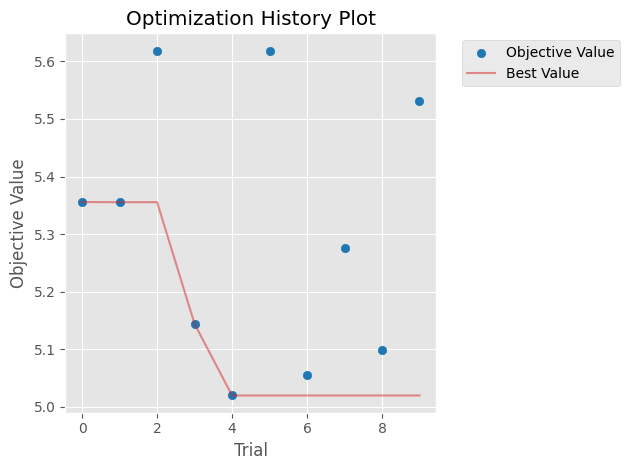

In [28]:
# Visualize optimization history
import matplotlib.pyplot as plt


# Optimization history
optuna.visualization.matplotlib.plot_optimization_history(study)





## Ideas clave

- **Tracking**: cada entrenamiento es un *run*.
  - Dentro del run, en `Artifacts`, puedes tener un modelo loggeado (por ejemplo `Artifacts/model`).

- **Registry**: es un “catálogo” por **nombre de modelo**.
  - Un mismo nombre (por ejemplo `nyc-taxi-duration-model`) puede tener versiones **v1, v2, v3...**
  - Cada versión apunta al run que la generó.

## ¿Qué vamos a hacer aquí?

1) Re-entrenar el mejor modelo (ya lo hicimos arriba).
2) Loggear el pipeline (preproceso + modelo) como artifact.
3) (Opcional) Crear/actualizar una **nueva versión** en el Registry con `registered_model_name=...`.
4) Asignar aliases:
- `candidate`: versión nueva (la que estás probando)
- `champion`: versión estable (la “mejor” aprobada)


# **Usando el model registry para guardar el mejor modelo y "ponerlo" en producción**

Podemos usar autlog de sklearn para captar la mayor cantidad de parametros y asi tener un modelo altamente replicable

La importancia del model registry es ya no solamente pensar en la experimentación, sino que al final, después de haber encontrado el mejor modelo pushearlo a nuestro model registry y poder usarlo en producción.

In [29]:
# Registrar y promover el mejor modelo (Model Registry)

import mlflow
from mlflow.tracking import MlflowClient
from mlflow.models.signature import infer_signature
from sklearn.pipeline import Pipeline

client = MlflowClient()

# Pipeline completo para producción (preprocesador + modelo)
pipeline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", best_model),
])

# Muestra pequeña de validación para inferir la signature del modelo

X_val_sample = df_val[["categorical_dict"] + numerical].head(50).copy()
pred_sample = pipeline_model.predict(X_val_sample)
signature = infer_signature(X_val_sample, pred_sample)


registered_name = "nyc-taxi-duration-model"

with mlflow.start_run(run_name="register_best_model"):
    mlflow.set_tag("stage", "register")
    mlflow.log_metric("rmse_val", rmse_best)

    # Un Pipeline con ColumnTransformer guarda internamente tipos como
    # numpy.dtype y sklearn.compose._column_transformer._RemainderColsList
    # para recordar qué hacer con las columnas. El formato skops (default
    # desde MLflow 3.15) los bloquea por seguridad si no los reconoce, con
    # el error "references untrusted types". Son tipos internos de
    # sklearn/numpy, no clases externas ni arbitrarias, así que es seguro
    # confiarlos explícitamente aquí.
    model_info = mlflow.sklearn.log_model(
        sk_model=pipeline_model,
        name="model",
        signature=signature,
        input_example=X_val_sample,
        registered_model_name=registered_name,
        skops_trusted_types=[
            "numpy.dtype",
            "sklearn.compose._column_transformer._RemainderColsList",
        ],
    )

model_uri = model_info.model_uri
print(f"Model URI: {model_uri}")

# Obtenemos la version recien creada. Usamos search_model_versions (metodo recomendado)
# en vez de get_latest_versions, que depende del sistema de stages ya deprecado.
versions = client.search_model_versions(f"name='{registered_name}'")
new_version = max(versions, key=lambda v: int(v.creation_timestamp)).version
print(f"New version: {new_version}")

2026/10/12 23:02:35 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/10/12 23:02:35 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/10/12 23:03:01 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Registered model 'nyc-taxi-duration-model' already exists. Creating a new version of this model...
2026/10/12 23:03:04 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: nyc-taxi-duration-model, version 2
Created version '2' of model 'nyc-taxi-duration-model'.
2026/10/12 23:03:04 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/10/12 23:03:04 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


🏃 View run register_best_model at: http://127.0.0.1:5000/#/experiments/6/runs/1f158894669b43f28437e922a93bea02
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/6
Model URI: models:/m-be9711ac054f46ce9c137839404bf06b
New version: 2


In [30]:
print(f"Version {new_version} registered successfully")
print("You can manually assign aliases later:")
print(f"  - Set as champion: client.set_registered_model_alias('{registered_name}', 'champion', '{new_version}')")
print(f"  - Set as candidate: client.set_registered_model_alias('{registered_name}', 'candidate', '{new_version}')")

print({"registered_name": registered_name, "version": new_version, "model_uri": model_uri})

Version 2 registered successfully
You can manually assign aliases later:
  - Set as champion: client.set_registered_model_alias('nyc-taxi-duration-model', 'champion', '2')
  - Set as candidate: client.set_registered_model_alias('nyc-taxi-duration-model', 'candidate', '2')
{'registered_name': 'nyc-taxi-duration-model', 'version': '2', 'model_uri': 'models:/m-be9711ac054f46ce9c137839404bf06b'}


In [31]:
client.set_registered_model_alias(registered_name, "champion", new_version)  # la version recien registrada


In [32]:
client = MlflowClient()
model = client.get_registered_model(registered_name)
print(model.aliases)  # {'champion': '6', 'candidate': '3'}

{'champion': '2'}


In [33]:
# Obtener qué versión tiene el alias "champion"
champion_version = client.get_model_version_by_alias(registered_name, "champion")
print(champion_version.version)  # Ejemplo: "6"

2


> **Nota:** el sistema de *stages* (`None -> Staging -> Production -> Archived`) esta
> deprecado en versiones recientes de MLflow. Lo vemos aqui solo para que lo reconozcan
> si trabajan con proyectos antiguos, pero en proyectos nuevos usen **aliases**
> (`champion`, `candidate`, etc.) como ya hicimos arriba.


In [21]:
# client.transition_model_version_stage(registered_name, champion_version.version, "Staging")

### Obtener modelo por versión:

In [34]:
model_uri = f"models:/nyc-taxi-duration-model/{new_version}"
model = mlflow.sklearn.load_model(model_uri)


In [35]:
model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat', DictVectorizer(),
                                                  'categorical_dict'),
                                                 ('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['trip_distance'])])),
                ('model',
                 RandomForestRegressor(max_depth=15, min_samples_leaf=4,
                                       min_samples_split=9, n_estimators=141,
                                       n_jobs=-1, random_state=42))])

In [36]:
X_val[0]

array([2.65000000e+02, 7.40000000e+01, 4.17239758e-03])

In [37]:
signature

inputs: 
  ['categorical_dict': {DOLocationID: long (required), PULocationID: long (required)} (required), 'trip_distance': double (required)]
outputs: 
  [Tensor('float64', (-1,))]
params: 
  None

In [38]:
X_sample = df_val[["categorical_dict"] + numerical].head(10)


In [39]:
X_sample

,categorical_dict,trip_distance
0,"{'PULocationID': 74, 'DOLocationID': 265}",10.80
1,"{'PULocationID': 216, 'DOLocationID': 196}",4.76
2,"{'PULocationID': 7, 'DOLocationID': 114}",6.32
3,"{'PULocationID': 74, 'DOLocationID': 239}",3.50
4,"{'PULocationID': 82, 'DOLocationID': 223}",3.14
6,"{'PULocationID': 92, 'DOLocationID': 121}",2.52
7,"{'PULocationID': 244, 'DOLocationID': 42}",1.96
8,"{'PULocationID': 75, 'DOLocationID': 41}",1.46
9,"{'PULocationID': 95, 'DOLocationID': 121}",2.38
10,"{'PULocationID': 97, 'DOLocationID': 97}",0.88


In [40]:
model.predict(X_sample)

array([23.68358444, 27.11027515, 30.66397555, 17.81616984, 15.10045184,
       12.58592035, 12.88209074,  7.326704  , 13.57780128, 10.13251786])

## Obtener el modelo usando el alias.version

In [41]:
champion_version = client.get_model_version_by_alias("nyc-taxi-duration-model", "champion")
model_uri = f"models:/nyc-taxi-duration-model/{champion_version.version}"
model = mlflow.sklearn.load_model(model_uri)

In [42]:
model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat', DictVectorizer(),
                                                  'categorical_dict'),
                                                 ('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['trip_distance'])])),
                ('model',
                 RandomForestRegressor(max_depth=15, min_samples_leaf=4,
                                       min_samples_split=9, n_estimators=141,
                                       n_jobs=-1, random_state=42))])

### Obtener modelo por stage (Staging, Production, Archived)

None -> Staging -> Production -> Archived


## Ejercicio Final (equipos - sala de Zoom)

**Modalidad:** equipos de 3-4 personas, sala de breakout en Zoom.
**Tiempo sugerido:** 30 minutos.

Ya vieron en clase tres formas distintas de trabajar con MLflow: el Escenario 1
(sin Tracking Server, todo en archivos locales), el Escenario 2 (servidor local
con SQLite) y este notebook (Tracking Server + autologging + Model Registry con
aliases). Este ejercicio integra las dos partes.

### Parte A: su propio experimento (15 min)

En equipo, sin copiar el espacio de búsqueda que ya usamos arriba:

1. Elijan un espacio de hiperparámetros propio para `RandomForestRegressor`
   (puede incluir hiperparámetros que no probamos arriba, como `max_features`).
2. Corran su propio estudio de Optuna con `n_trials=10` como mínimo, logueando
   cada trial en MLflow igual que hicimos en clase.
3. Asignen tags a la corrida (tipo de modelo, equipo responsable, etc.).
4. Registren el mejor modelo del equipo en el Model Registry, bajo un nombre
   propio (por ejemplo `nyc-taxi-duration-model-equipoX`), y asígnenle el alias
   `champion`.

### Parte B: comparando los tres escenarios (15 min)

En equipo, discutan y respondan:

1. En el Escenario 1 casi no pudieron usar el Model Registry, pero en este
   notebook sí. ¿Qué tuvo este notebook que el Escenario 1 no tenía, y que
   hizo posible usar el Registry?
2. Si dos equipos del curso le pusieran el mismo nombre a su experimento en
   un servidor compartido, ¿qué problema creen que pasaría? Escriban un
   nombre de experimento para su propio equipo que evite ese problema.
3. En este notebook, el mejor modelo tiene el alias `champion`. Si en vez de
   un alias tuvieran que acordarse "a mano" cuál versión del modelo es la
   buena, ¿qué podría salir mal?

**Entregable para la plenaria:** sus respuestas a las tres preguntas.


In [ ]:
# Espacio para el Ejercicio Final, Parte A: su propio estudio de Optuna +
# registro del mejor modelo.

# study_equipo = optuna.create_study(direction="minimize")
# ...


In [2]:
# ================================================================
# Ejercicio Final - Parte A: Estudio Optuna + Model Registry
# ================================================================

import json
import mlflow
import numpy as np
import optuna
from mlflow.models.signature import infer_signature
from mlflow.tracking import MlflowClient
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline

client = MlflowClient()


# 1. Definición de la función objetivo con espacio propio de hiperparámetros
def objective_equipo(trial):
  # --- Espacio propio (incluye max_features y max_samples) ---
  n_estimators = trial.suggest_int('n_estimators', 60, 240, step=30)
  max_depth = trial.suggest_int('max_depth', 8, 25)
  min_samples_split = trial.suggest_int('min_samples_split', 5, 25)
  min_samples_leaf = trial.suggest_int('min_samples_leaf', 2, 12)
  max_features = trial.suggest_float('max_features', 0.3, 0.9)
  max_samples = trial.suggest_float('max_samples', 0.6, 0.95)

  with mlflow.start_run(
      run_name=f'trial_equipo_{trial.number}', nested=True
  ) as run:
    # 3. Tags asignados a cada trial (child run)
    mlflow.set_tags({
        'model_type': 'RandomForestRegressor',
        'team': 'equipo_mlops',
        'stage': 'hpo_trial',
    })

    rf = RandomForestRegressor(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        max_samples=max_samples,
        bootstrap=True,
        random_state=42,
        n_jobs=-1,
    )

    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_val)
    rmse = float(np.sqrt(mean_squared_error(y_val, y_pred)))

    # Loggear métricas y parámetros
    mlflow.log_params(trial.params)
    mlflow.log_metric('rmse', rmse)

    # Registrar el modelo puntual de este trial
    model_info = mlflow.sklearn.log_model(rf, name='model')
    trial.set_user_attr('model_id', model_info.model_id)
    trial.set_user_attr('mlflow_run_id', run.info.run_id)

  return rmse


In [4]:
# 2. Correr estudio de Optuna con n_trials=10
experiment_name_equipo = 'nyc-taxi-hpo-equipo'
mlflow.set_experiment(experiment_name_equipo)

study_equipo = optuna.create_study(direction='minimize')

[I 2026-10-12 23:10:34,559] A new study created in memory with name: no-name-fac0c194-50a8-4622-b305-3c047b92ecd6


In [6]:
  with mlflow.start_run(
      run_name=f'trial_equipo_{trial.number}', nested=True
  ) as run:
    # 3. Tags asignados a cada trial (child run)
    mlflow.set_tags({
        'model_type': 'RandomForestRegressor',
        'team': 'equipo_mlops',
        'stage': 'hpo_trial',
    })
    rf = RandomForestRegressor(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        max_samples=max_samples,
        bootstrap=True,
        random_state=42,
        n_jobs=-1,
    )
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_val)
    rmse = float(np.sqrt(mean_squared_error(y_val, y_pred)))

NameError: name 'trial' is not defined

In [7]:
# ================================================================
# Ejercicio Final - Parte A: Estudio Optuna + Model Registry
# ================================================================

import json
import mlflow
import numpy as np
import optuna
from mlflow.models.signature import infer_signature
from mlflow.tracking import MlflowClient
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline

client = MlflowClient()


# 1. Definición de la función objetivo con espacio propio de hiperparámetros
def objective_equipo(trial):
  # --- Espacio propio (incluye max_features y max_samples) ---
  n_estimators = trial.suggest_int('n_estimators', 60, 240, step=30)
  max_depth = trial.suggest_int('max_depth', 8, 25)
  min_samples_split = trial.suggest_int('min_samples_split', 5, 25)
  min_samples_leaf = trial.suggest_int('min_samples_leaf', 2, 12)
  max_features = trial.suggest_float('max_features', 0.3, 0.9)
  max_samples = trial.suggest_float('max_samples', 0.6, 0.95)

  with mlflow.start_run(
      run_name=f'trial_equipo_{trial.number}', nested=True
  ) as run:
    # 3. Tags asignados a cada trial (child run)
    mlflow.set_tags({
        'model_type': 'RandomForestRegressor',
        'team': 'equipo_mlops',
        'stage': 'hpo_trial',
    })

    rf = RandomForestRegressor(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        max_samples=max_samples,
        bootstrap=True,
        random_state=42,
        n_jobs=-1,
    )

    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_val)
    rmse = float(np.sqrt(mean_squared_error(y_val, y_pred)))

    # Loggear métricas y parámetros
    mlflow.log_params(trial.params)
    mlflow.log_metric('rmse', rmse)

    # Registrar el modelo puntual de este trial
    model_info = mlflow.sklearn.log_model(rf, name='model')
    trial.set_user_attr('model_id', model_info.model_id)
    trial.set_user_attr('mlflow_run_id', run.info.run_id)

  return rmse


# 2. Correr estudio de Optuna con n_trials=10
experiment_name_equipo = 'nyc-taxi-hpo-equipo'
mlflow.set_experiment(experiment_name_equipo)

study_equipo = optuna.create_study(direction='minimize')

with mlflow.start_run(run_name='optuna_study_equipo') as parent_run:
  # 3. Tags asignados a la corrida principal (parent run)
  mlflow.set_tags({
      'team': 'equipo_mlops',
      'search_strategy': 'optuna_tpe',
      'model_family': 'random_forest',
  })

  study_equipo.optimize(objective_equipo, n_trials=10)

  # Guardar artifacts de los mejores trials
  top_trials = sorted(study_equipo.trials, key=lambda t: t.value)[:5]
  top_trials_data = [
      {
          'trial_number': t.number,
          'rmse': t.value,
          'params': t.params,
          'model_id': t.user_attrs.get('model_id'),
          'mlflow_run_id': t.user_attrs.get('mlflow_run_id'),
      }
      for t in top_trials
  ]

  mlflow.log_dict(top_trials_data, 'optuna_equipo_top_trials.csv')
  mlflow.log_dict(study_equipo.best_params, 'optuna_equipo_best_params.json')

  print(f'✅ Estudio completado. Mejor RMSE: {study_equipo.best_value:.4f}')
  print(f'Mejores parámetros: {json.dumps(study_equipo.best_params, indent=2)}')

# 4. Registrar el mejor modelo en el Model Registry como champion
best_params_equipo = {
    **study_equipo.best_params,
    'random_state': 42,
    'n_jobs': -1,
    'bootstrap': True,
}
best_model_equipo = RandomForestRegressor(**best_params_equipo)
best_model_equipo.fit(X_train, y_train)
y_pred_best = best_model_equipo.predict(X_val)
rmse_best_equipo = float(np.sqrt(mean_squared_error(y_val, y_pred_best)))

# Pipeline completo de producción (preprocesador + modelo ganador)
pipeline_equipo = Pipeline([
    ('preprocessor', preprocessor),
    ('model', best_model_equipo),
])

# Inferir firma
X_val_sample = df_val[['categorical_dict'] + numerical].head(50).copy()
pred_sample = pipeline_equipo.predict(X_val_sample)
signature = infer_signature(X_val_sample, pred_sample)

registered_name_equipo = 'nyc-taxi-duration-model-equipo'

with mlflow.start_run(run_name='register_best_model_equipo'):
  mlflow.set_tag('team', 'equipo_mlops')
  mlflow.set_tag('stage', 'register')
  mlflow.log_metric('rmse_val', rmse_best_equipo)

  model_info = mlflow.sklearn.log_model(
      sk_model=pipeline_equipo,
      name='model',
      signature=signature,
      input_example=X_val_sample,
      registered_model_name=registered_name_equipo,
      skops_trusted_types=[
          'numpy.dtype',
          'sklearn.compose._column_transformer._RemainderColsList',
      ],
  )

# Asignar alias champion a la nueva versión
versions = client.search_model_versions(f"name='{registered_name_equipo}'")
new_version_equipo = max(
    versions, key=lambda v: int(v.creation_timestamp)
).version
client.set_registered_model_alias(
    registered_name_equipo, 'champion', new_version_equipo
)

print(
    f"🏆 Modelo '{registered_name_equipo}' registrado en versión"
    f" {new_version_equipo} con alias 'champion'!"
)

[I 2026-10-12 23:16:10,656] A new study created in memory with name: no-name-f4a0952f-5d2b-49ea-8f29-f945130344a0
[W 2026-10-12 23:16:11,104] Trial 0 failed with parameters: {'n_estimators': 150, 'max_depth': 22, 'min_samples_split': 15, 'min_samples_leaf': 11, 'max_features': 0.7329064945297401, 'max_samples': 0.8027879271984159} because of the following error: NameError("name 'X_train' is not defined").
Traceback (most recent call last):
  File "c:\Users\USUARIO\MLOps\.venv\Lib\site-packages\optuna\study\_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
                      ^^^^^^^^^^^
  File "C:\Users\USUARIO\AppData\Local\Temp\ipykernel_18780\2546958626.py", line 50, in objective_equipo
    rf.fit(X_train, y_train)
           ^^^^^^^
NameError: name 'X_train' is not defined
[W 2026-10-12 23:16:11,108] Trial 0 failed with value None.


NameError: name 'X_train' is not defined